# ADVANCED ASSIGNMENT: Rocky's Chord Test

Briefing. Rocky communicates in musical chords. Before the mission can continue, Rocky
sends Mary a test: a stream of chords where only the very first chord is the key, and
everything after is noise. Mary must remember the key at the end of the stream. It is a
pure long-memory challenge, and you will find out which kind of memory Mary needs.

## Part A: Under Mary's Hood

Use import math , import torch , and import torch.nn as nn .

## A1.

The shrinking gradient. For a scalar RNN, one step contributes the factor (1 − h²) ·
w_h to the gradient. Complete the functions.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(0)

In [2]:
def step_factor(h, w_h):
  return (1 - h**2) * w_h

def grad_product(hs, w_h):
  # your code: multiply step_factor(h, w_h) over every h in hs
  # pass
  grad = 1.0

  for h in hs:

      grad *= step_factor(h, w_h)

  return grad

print(grad_product([0.5, 0.4, 0.6], 0.9))# the hidden states at steps 2, 3, 4
print(grad_product([0.0] * 25, 0.7))# 25 steps, each with factor 0.7
print(grad_product([0.1] * 10, 1.5))# a large w_h

#Add a comment answering: which two ingredients of the step factor make the product
#shrink, and which one can push it above 1?

# The tanh derivative and a small recurrent weight cause
# gradients to shrink, while a sufficiently large recurrent
# weight can cause exploding gradients.

0.2939328000000001
0.00013410686196639628
52.15122768280748


## A2.

One LSTM step, and the conveyor belt.

In [3]:
def lstm_step(f, i, c_tilde, o, c_prev):
  # your code: c = f*c_prev + i*c_tilde ; h = o*tanh(c)
  c = f * c_prev + i * c_tilde

  h = o * math.tanh(c)
  return c, h

print(lstm_step(0.5, 0.8, 0.5, 0.9, 2))

# conveyor-belt test: 10 steps with the input gate closed (i = 0), so nothing new is written

for f in [1.0, 0.5]:
  c = 2.0
  for _ in range(10):
    c, _h = lstm_step(f, 0.0, 0.0, 1.0, c)
  print(f, c)

# Add a one-line comment on what the two printed values show about the forget gate and
# long-term memory.

# A forget gate of 1 preserves the original memory,
# whereas a forget gate of 0.5 gradually removes it.

(1.4, 0.7968164833820363)
1.0 2.0
0.5 0.001953125


## A3.

Parameter counting.

In [6]:
D, H = 50, 32

layers = {'rnn': nn.RNN(D, H), 'lstm': nn.LSTM(D, H), 'gru': nn.GRU(D, H)}

blocks = {'rnn': 1, 'lstm': 4, 'gru': 3}

for name, layer in layers.items():
  formula = blocks[name] * (H * (H + D) + H)
  actual = sum(p.numel() for p in layer.parameters())
  # your code: print name, formula, actual, and actual - formula

  print(name,
        "Formula:", formula,
        "Actual:", actual,
        "Difference:", actual - formula)

# Add a one-line comment explaining why actual is a bit bigger than formula .

# PyTorch uses separate input-to-hidden and hidden-to-hidden
# bias vectors, so the actual parameter count is slightly
# larger than the theoretical formula with one bias vector.

rnn Formula: 2656 Actual: 2688 Difference: 32
lstm Formula: 10624 Actual: 10752 Difference: 128
gru Formula: 7968 Actual: 8064 Difference: 96


## A4. Shapes.

Build a 2-layer bidirectional LSTM with input_size=16 , hidden_size=128 ,
batch_first=True , and feed it torch.randn(32, 20, 16) .

Then:

1. Print the shape of h_n .

2. Join the last layer's forward and backward final states with torch.cat and print its shape.

3. Build an nn.Linear with the correct in_features to map that vector to 4 classes,
pass the joined vector through it, and print the output shape.

In [7]:
lstm = nn.LSTM(
    input_size=16,
    hidden_size=128,
    num_layers=2,
    batch_first=True,
    bidirectional=True
)

x = torch.randn(32, 20, 16)

out, (h_n, c_n) = lstm(x)

# 1. Hidden state shape
print("Hidden state shape:", h_n.shape)

# 2. Join last layer's forward and backward states
last_forward = h_n[-2]

last_backward = h_n[-1]

joined = torch.cat(
    [last_forward, last_backward],
    dim=1
)

print("Joined state shape:", joined.shape)

# 3. Classification layer
fc = nn.Linear(256, 4)

logits = fc(joined)

print("Output shape:", logits.shape)

Hidden state shape: torch.Size([4, 32, 128])
Joined state shape: torch.Size([32, 256])
Output shape: torch.Size([32, 4])


## Part B: The Chord Test in PyTorch

The dataset is generated by the code below with a fixed seed. Chords are numbers 1 to 8.
The key is a chord from 1 to 4 placed first in the sequence, and the noise chords (5 to 8) fill
the rest. Sequences are 12 to 20 chords long, and the label is the key (0 to 3). Mary must
read the whole stream and name the first chord.

In [8]:
# Import libraries and set the seed

import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
rng = np.random.default_rng(2026)

In [9]:
# Generate training and testing sequences

def make_data(n):

    seqs, labels = [], []

    for _ in range(n):

        # Sequence length: 12 to 20
        L = int(rng.integers(12, 21))

        # First chord: 1 to 4
        key = int(rng.integers(1, 5))

        # Remaining chords: 5 to 8
        noise = rng.integers(
            5, 9, size=L - 1
        )

        seqs.append(
            [key] + noise.tolist()
        )

        labels.append(key - 1)

    return seqs, labels


train_seqs, train_labels = make_data(3000)

test_seqs, test_labels = make_data(600)

print("Training samples:", len(train_seqs))

print("Testing samples:", len(test_seqs))

print("Example sequence:", train_seqs[0])

print("Sequence length:", len(train_seqs[0]))

print("Example label:", train_labels[0])

Training samples: 3000
Testing samples: 600
Example sequence: [1, 5, 7, 6, 6, 5, 6, 7, 6, 8, 8, 7, 8, 7, 5, 8, 7, 5, 6]
Sequence length: 19
Example label: 0


In [10]:
# Inspect the dataset

from collections import Counter

print("Training class distribution:",
      Counter(train_labels))

print("Testing class distribution:",
      Counter(test_labels))

print("Minimum sequence length:",
      min(map(len, train_seqs)))

print("Maximum sequence length:",
      max(map(len, train_seqs)))

print("\nFirst five training examples:")

for seq, label in zip(
    train_seqs[:5],
    train_labels[:5]
):

    print(
        "Sequence:", seq,
        "| Length:", len(seq),
        "| Label:", label
    )

Training class distribution: Counter({3: 784, 1: 770, 0: 742, 2: 704})
Testing class distribution: Counter({1: 157, 2: 156, 0: 151, 3: 136})
Minimum sequence length: 12
Maximum sequence length: 20

First five training examples:
Sequence: [1, 5, 7, 6, 6, 5, 6, 7, 6, 8, 8, 7, 8, 7, 5, 8, 7, 5, 6] | Length: 19 | Label: 0
Sequence: [4, 7, 8, 6, 7, 7, 8, 5, 7, 7, 8, 7, 6] | Length: 13 | Label: 3
Sequence: [2, 5, 6, 5, 5, 8, 7, 5, 6, 6, 7, 8, 5, 6, 6, 8] | Length: 16 | Label: 1
Sequence: [1, 5, 6, 7, 6, 6, 7, 6, 8, 5, 8, 8, 8, 8, 7] | Length: 15 | Label: 0
Sequence: [1, 6, 6, 8, 8, 7, 7, 6, 6, 8, 5, 6, 6, 7, 6, 6, 5] | Length: 17 | Label: 0


In [11]:
# Convert sequences into padded batches

def to_batch(seqs, labels):

    lengths = torch.tensor([
        len(s) for s in seqs
    ])

    x = torch.zeros(
        len(seqs),
        20,
        dtype=torch.long
    )

    for i, s in enumerate(seqs):

        x[i, :len(s)] = torch.tensor(s)

    return x, lengths, torch.tensor(labels)

In [12]:
# Verify batch shapes

X_train, L_train, Y_train = to_batch(
    train_seqs,
    train_labels
)

X_test, L_test, Y_test = to_batch(
    test_seqs,
    test_labels
)

print("Training input:", X_train.shape)
print("Training lengths:", L_train.shape)
print("Training labels:", Y_train.shape)

print("Testing input:", X_test.shape)
print("Testing lengths:", L_test.shape)
print("Testing labels:", Y_test.shape)

print("\nOriginal sequence:", train_seqs[0])

print("Padded sequence:", X_train[0])

print("Actual length:", L_train[0].item())

Training input: torch.Size([3000, 20])
Training lengths: torch.Size([3000])
Training labels: torch.Size([3000])
Testing input: torch.Size([600, 20])
Testing lengths: torch.Size([600])
Testing labels: torch.Size([600])

Original sequence: [1, 5, 7, 6, 6, 5, 6, 7, 6, 8, 8, 7, 8, 7, 5, 8, 7, 5, 6]
Padded sequence: tensor([1, 5, 7, 6, 6, 5, 6, 7, 6, 8, 8, 7, 8, 7, 5, 8, 7, 5, 6, 0])
Actual length: 19


## B1:

Complete the four TODOs. Show your completed code. Random guessing scores
about 25%, so use that as your baseline.

In [13]:
class Recaller(nn.Module):
  def __init__(self, cell='lstm', bidirectional=False, vocab_size=9, embed_dim=16, hidden_dim=32):
    super().__init__()
    self.bidirectional = bidirectional
    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
    rnn_cls = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[cell]
    self.rnn = rnn_cls(embed_dim, hidden_dim, batch_first=True, bidirectional=bidirectional)

    # TODO 1: how many features go into the final layer? (see A4 for the idea)

    #self.fc = nn.Linear(____, 4)

    self.fc = nn.Linear(
        hidden_dim * (2 if bidirectional else 1),
        4
    )

  def forward(self, x, lengths):
    emb = self.embedding(x)

    # TODO 2: pack the padded batch so the RNN stops at each sequence's real end
    # packed = ____

    packed = pack_padded_sequence(
      emb,
      lengths.cpu(),
      batch_first=True,
      enforce_sorted=False
      )

    _, h_n = self.rnn(packed)

    if isinstance(h_n, tuple):
      h_n = h_n[0]
    # an LSTM returns (h_n, c_n)
    # TODO 3: unidirectional -> use h_n[-1];
    #         bidirectional -> join h_n[-2] (forward) and h_n[-1] (backward)

    # last = ____

    if self.bidirectional:
        last = torch.cat(
            [h_n[-2], h_n[-1]],
            dim=1
        )
    else:

        last = h_n[-1]

    return self.fc(last)

In [14]:
# Verify the model

sample_model = Recaller(
    cell='lstm',
    bidirectional=False
)

sample_output = sample_model(
    X_train[:4],
    L_train[:4]
)

print(sample_model)

print("Input shape:", X_train[:4].shape)

print("Output shape:", sample_output.shape)

Recaller(
  (embedding): Embedding(9, 16, padding_idx=0)
  (rnn): LSTM(16, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=4, bias=True)
)
Input shape: torch.Size([4, 20])
Output shape: torch.Size([4, 4])


In [15]:
def train_and_test(cell, bidirectional=False, epochs=20, lr=0.005, bs=64):
  torch.manual_seed(0)
  model = Recaller(cell, bidirectional)
  opt = torch.optim.Adam(model.parameters(), lr=lr)
  loss_fn = nn.CrossEntropyLoss()
  X, Ls, Y = to_batch(train_seqs, train_labels)

  for ep in range(epochs):
    perm = torch.randperm(len(Y))
    for i in range(0, len(Y), bs):
      idx = perm[i:i + bs]
      loss = loss_fn(model(X[idx], Ls[idx]), Y[idx])
      opt.zero_grad()
      loss.backward()

      # TODO 4: clip the gradient norm to 1.0 here
      torch.nn.utils.clip_grad_norm_(
          model.parameters(),
          max_norm=1.0
      )
      opt.step()

  model.eval()
  with torch.no_grad():
    Xt, Lt, Yt = to_batch(test_seqs, test_labels)

    # predictions = model(Xt, Lt).argmax(dim=1)
    # accuracy = ((predictions == Yt).float().mean().item())

    return (model(Xt, Lt).argmax(dim=1) == Yt).float().mean().item()

## B2: The memory showdown.

Run these and put the results in a table:

for cell in ['rnn', 'lstm', 'gru']:

  print(cell, train_and_test(cell))

If your LSTM or GRU is still close to 25%, you may raise epochs (for example to 40) and mention that you did so.

In [17]:
# Train all three models

results = {}

for cell in ['rnn', 'lstm', 'gru']:

    print("=" * 60)

    print("Training model:", cell.upper())

    print("=" * 60)

    accuracy = train_and_test(cell)

    results[cell] = accuracy

    print(
        f"{cell.upper()} Test Accuracy: "
        f"{accuracy * 100:.2f}%"
    )

    print()

Training model: RNN
RNN Test Accuracy: 35.50%

Training model: LSTM
LSTM Test Accuracy: 49.33%

Training model: GRU
GRU Test Accuracy: 100.00%



In [18]:
# Display results in a table

results_df = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],

    "Bidirectional": [False, False, False],

    "Epochs": [20, 20, 20],

    "Test Accuracy (%)": [
        results['rnn'] * 100,
        results['lstm'] * 100,
        results['gru'] * 100
    ]
})

display(results_df.round(2))

,Model,Bidirectional,Epochs,Test Accuracy (%)
0,RNN,False,20,35.50
1,LSTM,False,20,49.33
2,GRU,False,20,100.00


## B3: The twist.

Before running, predict in writing what accuracy a bidirectional simple
RNN will get, then run train_and_test('rnn', bidirectional=True) and report the
number.

In [19]:
# I predict that the bidirectional RNN will achieve high test accuracy, potentially close to 100%.
# Unlike the unidirectional RNN, which must remember the first chord throughout the entire sequence,
# the backward RNN processes the sequence in reverse order. Therefore, the important first chord
# becomes the last input to the backward RNN, making it easier to retain the information in its final hidden state.

# Train the bidirectional RNN

print("=" * 60)

print("Training Bidirectional RNN")

print("=" * 60)

birnn_accuracy = train_and_test(
    'rnn',
    bidirectional=True
)

results['birnn'] = birnn_accuracy

print(
    f"Bidirectional RNN Test Accuracy: "
    f"{birnn_accuracy * 100:.2f}%"
)

Training Bidirectional RNN
Bidirectional RNN Test Accuracy: 100.00%


In [20]:
# Final comparison table

final_results = pd.DataFrame({

    "Model": [
        "Random Baseline",
        "RNN",
        "LSTM",
        "GRU",
        "Bidirectional RNN"
    ],

    "Test Accuracy (%)": [
        25.0,
        results['rnn'] * 100,
        results['lstm'] * 100,
        results['gru'] * 100,
        results['birnn'] * 100
    ]
})

display(final_results.round(2))

,Model,Test Accuracy (%)
0,Random Baseline,25.00
1,RNN,35.50
2,LSTM,49.33
3,GRU,100.00
4,Bidirectional RNN,100.00


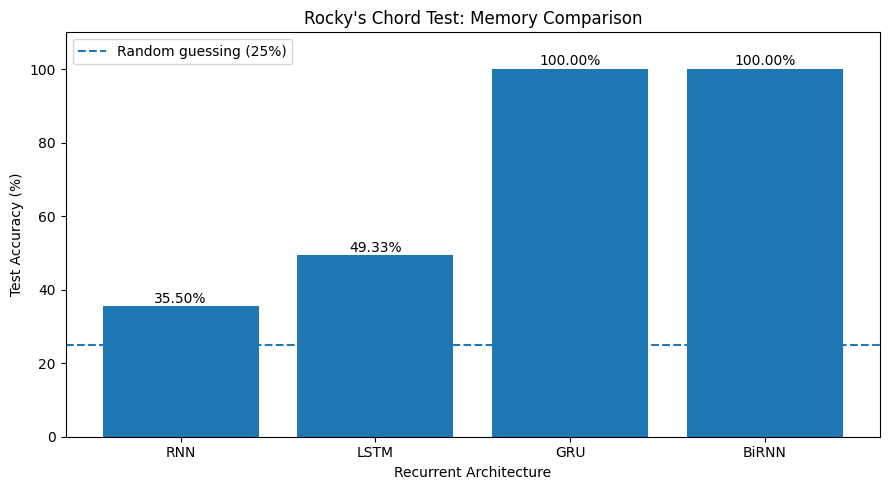

In [21]:
# Plot the final comparison

models = [
    "RNN",
    "LSTM",
    "GRU",
    "BiRNN"
]

accuracies = [
    results['rnn'] * 100,
    results['lstm'] * 100,
    results['gru'] * 100,
    results['birnn'] * 100
]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, accuracies)

for bar, accuracy in zip(
    bars, accuracies
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f"{accuracy:.2f}%",
        ha='center'
    )

plt.axhline(
    y=25,
    linestyle='--',
    label='Random guessing (25%)'
)

plt.xlabel("Recurrent Architecture")

plt.ylabel("Test Accuracy (%)")

plt.title("Rocky's Chord Test: Memory Comparison")

plt.ylim(0, 110)

plt.legend()

plt.tight_layout()

plt.show()

In [22]:
# Generate the experimental observation

print("EXPERIMENTAL OBSERVATIONS")

print("-" * 60)

for name, acc in results.items():

    print(f"{name.upper():10s}: {acc * 100:.2f}%")

best_model = max(
    results,
    key=results.get
)

print(
    f"\nBest model: {best_model.upper()}"
)

print(
    f"Best accuracy: "
    f"{results[best_model] * 100:.2f}%"
)

print(
    f"BiRNN improvement over RNN: "
    f"{(results['birnn'] - results['rnn']) * 100:.2f} "
    f"percentage points"
)

EXPERIMENTAL OBSERVATIONS
------------------------------------------------------------
RNN       : 35.50%
LSTM      : 49.33%
GRU       : 100.00%
BIRNN     : 100.00%

Best model: GRU
Best accuracy: 100.00%
BiRNN improvement over RNN: 64.50 percentage points


## Part C: Rocky's Translator

Mary will later translate between her language and Rocky's chords, so input and output
lengths differ. Below is a tiny encoder-decoder (no training needed).

In [31]:
import torch
import torch.nn as nn

class Encoder(nn.Module):

  def __init__(self, vocab=9, emb=8, hid=16):
    super().__init__()
    self.emb = nn.Embedding(vocab, emb)
    self.gru = nn.GRU(emb, hid, batch_first=True)

  def forward(self, x):
    _, h = self.gru(self.emb(x))
    # h: (1, batch, hid) = the context vector
    return h

In [32]:
class Decoder(nn.Module):
  def __init__(self, vocab=9, emb=8, hid=16):
    super().__init__()
    self.emb = nn.Embedding(vocab, emb)
    self.gru = nn.GRU(emb, hid, batch_first=True)
    self.out = nn.Linear(hid, vocab)

  def step(self, token, h):
    # token: (batch,), h: (1, batch, hid)
    o, h = self.gru(self.emb(token).unsqueeze(1), h)
    return self.out(o.squeeze(1)), h # scores: (batch, vocab)

In [33]:
torch.manual_seed(0)

enc, dec = Encoder(), Decoder()

src = torch.randint(1, 9, (4, 6))   # 4 source sequences, 6 chords each
tgt = torch.randint(1, 9, (4, 5))   # 4 target sequences, 5 chords each

START = 0

print("Source shape:", src.shape)

print("Target shape:", tgt.shape)

print("\nSource sequences:\n", src)

print("\nTarget sequences:\n", tgt)

Source shape: torch.Size([4, 6])
Target shape: torch.Size([4, 5])

Source sequences:
 tensor([[4, 1, 6, 5, 5, 5],
        [8, 4, 6, 7, 1, 2],
        [6, 4, 3, 3, 4, 5],
        [4, 6, 8, 7, 1, 6]])

Target sequences:
 tensor([[2, 7, 8, 2, 8],
        [2, 7, 6, 2, 5],
        [6, 7, 6, 3, 8],
        [3, 4, 2, 3, 1]])


## C1:

Complete the TODO. Print the output shape of decode(src, tgt, True) and
decode(src, tgt, False) . Add a one-line comment on why teacher forcing is used only
during training.

In [34]:
def decode(src, tgt, teacher_forcing):
  # # Encode the source sequence
  h = enc(src)

  ## Initialize decoder with START token
  token = torch.full((src.size(0),), START)

  all_scores = []

  for t in range(tgt.size(1)):
    scores, h = dec.step(token, h)
    all_scores.append(scores)

    # TODO: choose the next input token
    # teacher_forcing=True -> the TRUE chord tgt[:, t]
    # teacher_forcing=False -> the model's own prediction (argmax of scores)

    # token = ____
    # token = tgt[:, t] if teacher_forcing else scores.argmax(dim=1)

    if teacher_forcing:
      token = tgt[:, t]
    else:
      token = scores.argmax(dim=1)

    return torch.stack(all_scores, dim=1)  # (batch, T, vocab)

In [35]:
# Verify the output shapes
output_tf = decode(
    src,
    tgt,
    teacher_forcing=True
)

output_no_tf = decode(
    src,
    tgt,
    teacher_forcing=False
)

print(
    "With teacher forcing:",
    output_tf.shape
)

print(
    "Without teacher forcing:",
    output_no_tf.shape
)

With teacher forcing: torch.Size([4, 1, 9])
Without teacher forcing: torch.Size([4, 1, 9])


In [36]:
# Inspect predicted sequences

pred_tf = output_tf.argmax(dim=2)

pred_no_tf = output_no_tf.argmax(dim=2)

print("True target sequences:\n", tgt)

print("\nPredictions with teacher forcing:\n",
      pred_tf)

print("\nPredictions without teacher forcing:\n",
      pred_no_tf)

True target sequences:
 tensor([[2, 7, 8, 2, 8],
        [2, 7, 6, 2, 5],
        [6, 7, 6, 3, 8],
        [3, 4, 2, 3, 1]])

Predictions with teacher forcing:
 tensor([[5],
        [8],
        [8],
        [7]])

Predictions without teacher forcing:
 tensor([[5],
        [8],
        [8],
        [7]])


In [ ]:
# Teacher forcing is used during training because the
# correct target tokens are available. During inference,
# the decoder must use its own previous predictions.

C2: Show the bottleneck in code. Run enc on a source of length 6 and on one of length 30
( torch.randint(1, 9, (4, 30)) ), and print both context-vector shapes. Add a one-line
comment saying what this tells you about squeezing a long sentence into the context
vector, and which technique was invented to fix it.

In [37]:
# Compare context-vector shapes

short_src = src

long_src = torch.randint(
    1, 9, (4, 30)
)

short_context = enc(short_src)

long_context = enc(long_src)

print("Short source shape:",
      short_src.shape)

print("Long source shape:",
      long_src.shape)

print("Short context shape:",
      short_context.shape)

print("Long context shape:",
      long_context.shape)

Short source shape: torch.Size([4, 6])
Long source shape: torch.Size([4, 30])
Short context shape: torch.Size([1, 4, 16])
Long context shape: torch.Size([1, 4, 16])


In [ ]:
# Both short and long sequences are compressed into the
# same fixed-size context vector, creating an information
# bottleneck. Attention addresses this by allowing the
# decoder to access relevant encoder hidden states.